In [1]:
import os

# Convert the raw UCI .txt (';'-separated, '?' = missing) to CSV once
if not os.path.exists('household_power_consumption.csv'):
    with open('household_power_consumption.txt', newline='') as src, open('household_power_consumption.csv', 'w', newline='') as dst:
        for line in src:
            dst.write(line.replace(';', ',').replace('?', ''))

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('household_power_consumption.csv')
df['Datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], format='%d/%m/%Y %H:%M:%S')
df = df.drop(columns=['Date', 'Time']).set_index('Datetime')
df.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


### GPU check
Confirms which device PyTorch will train on. Every model below is moved to `device`.

In [3]:
import random
import numpy as np
import torch

print('PyTorch', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
print('CUDA version:', torch.version.cuda, '| cuDNN version:', torch.backends.cudnn.version())

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cuda':
    print('Training on GPU:', torch.cuda.get_device_name(0))
else:
    print('No GPU found, training on CPU')

# A small matmul proves tensors actually land on the chosen device
probe = torch.randn(256, 256, device=device)
print('Test matmul ran on:', (probe @ probe).device)

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)  # also seeds CUDA

# Deterministic cuDNN kernels so GPU runs repeat exactly with the same seed
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
set_seed()

PyTorch 2.14.1+cu126
CUDA available: True
CUDA version: 12.6 | cuDNN version: 91002
Training on GPU: NVIDIA RTX A2000
Test matmul ran on: cuda:0


## Basic investigation

In [4]:
print('Shape:', df.shape)
print('Range:', df.index.min(), '->', df.index.max())
print('Timestamps unique and evenly spaced (1 min):', df.index.is_unique and (df.index.to_series().diff().dropna() == pd.Timedelta('1min')).all())
df.info()

Shape: (2075259, 7)
Range: 2006-12-16 17:24:00 -> 2010-11-26 21:02:00
Timestamps unique and evenly spaced (1 min): True
<class 'pandas.DataFrame'>
DatetimeIndex: 2075259 entries, 2006-12-16 17:24:00 to 2010-11-26 21:02:00
Data columns (total 7 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Global_active_power    float64
 1   Global_reactive_power  float64
 2   Voltage                float64
 3   Global_intensity       float64
 4   Sub_metering_1         float64
 5   Sub_metering_2         float64
 6   Sub_metering_3         float64
dtypes: float64(7)
memory usage: 126.7 MB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Global_active_power,2049280.0,1.091615,1.057294,0.076,0.308,0.602,1.528,11.122
Global_reactive_power,2049280.0,0.123714,0.112722,0.000,0.048,0.100,0.194,1.390
Voltage,2049280.0,240.839858,3.239987,223.200,238.990,241.010,242.890,254.150
Global_intensity,2049280.0,4.627759,4.444396,0.200,1.400,2.600,6.400,48.400
Sub_metering_1,2049280.0,1.121923,6.153031,0.000,0.000,0.000,0.000,88.000
Sub_metering_2,2049280.0,1.298520,5.822026,0.000,0.000,0.000,1.000,80.000
Sub_metering_3,2049280.0,6.458447,8.437154,0.000,0.000,1.000,17.000,31.000


### Missing values

In [6]:
missing = df.isna()
print('Missing per column:')
print(missing.sum())
print(f'\nRows with any missing: {missing.any(axis=1).sum()} ({missing.any(axis=1).mean():.2%})')

# Missing values come in contiguous gaps; list the longest ones
row_missing = missing.any(axis=1)
gap_id = (row_missing != row_missing.shift()).cumsum()
gaps = row_missing[row_missing].groupby(gap_id[row_missing]).agg(
    start=lambda s: s.index.min(), end=lambda s: s.index.max(), minutes='size')
print(f'\nNumber of gaps: {len(gaps)}')
gaps.sort_values('minutes', ascending=False).head(10).reset_index(drop=True)

Missing per column:
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

Rows with any missing: 25979 (1.25%)

Number of gaps: 71


,start,end,minutes
0,2010-08-17 21:02:00,2010-08-22 21:27:00,7226
1,2010-09-25 03:56:00,2010-09-28 19:12:00,5237
2,2007-04-28 00:21:00,2007-04-30 14:23:00,3723
3,2009-06-13 00:30:00,2009-06-15 07:34:00,3305
4,2010-01-12 14:53:00,2010-01-14 19:01:00,3129
5,2010-03-20 03:52:00,2010-03-21 13:38:00,2027
6,2009-08-13 05:00:00,2009-08-13 19:50:00,891
7,2007-07-15 16:49:00,2007-07-15 18:11:00,83
8,2008-12-10 10:48:00,2008-12-10 11:57:00,70
9,2007-07-15 18:21:00,2007-07-15 19:07:00,47


### Distributions

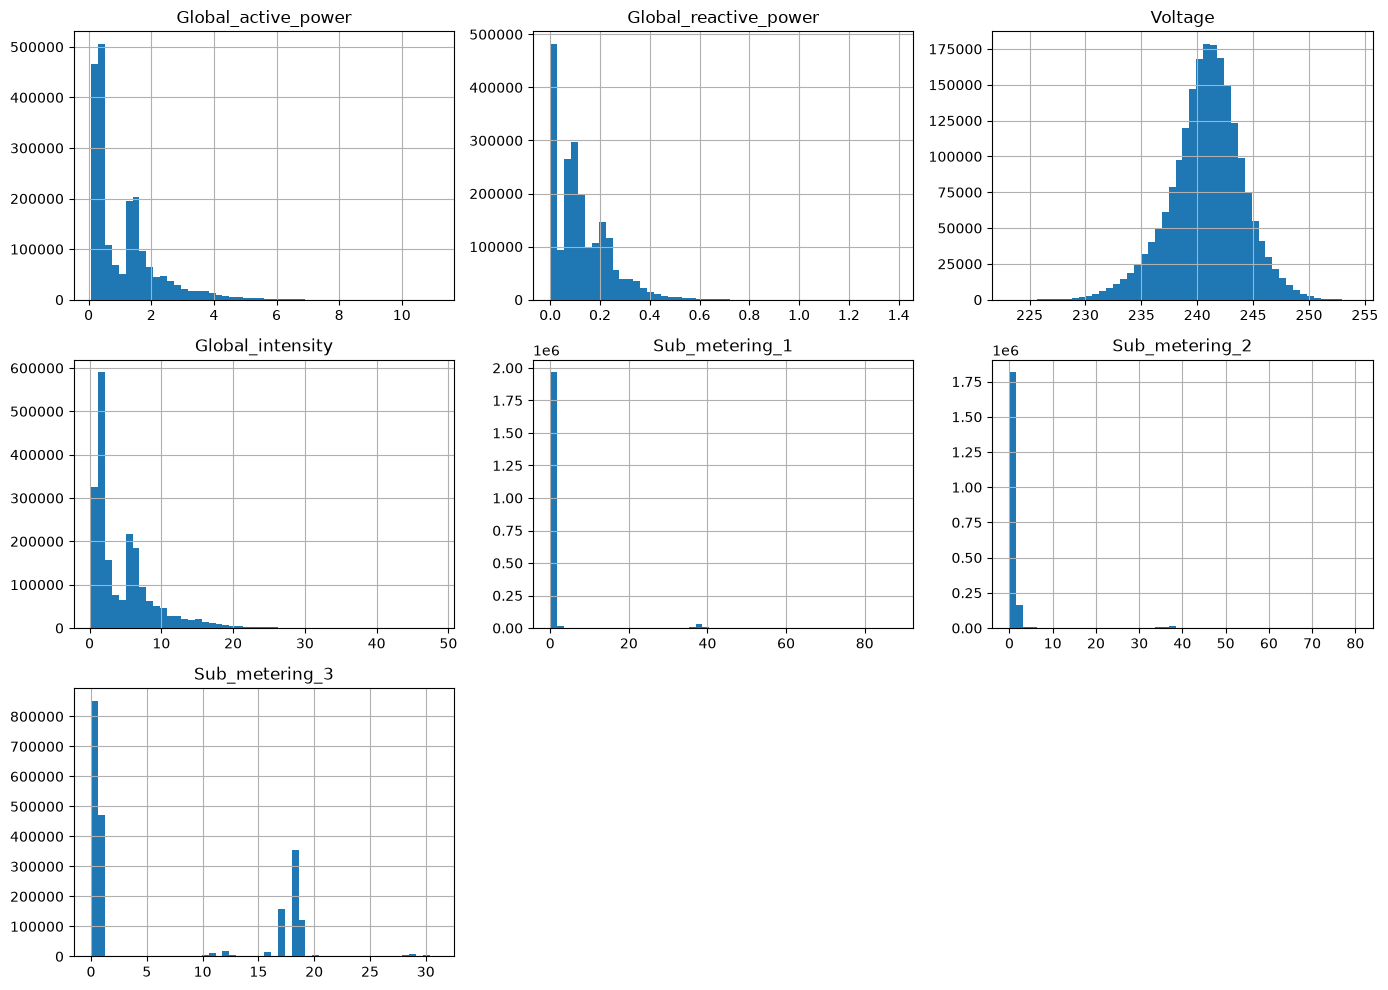

In [7]:
df.hist(bins=50, figsize=(14, 10))
plt.tight_layout()
plt.show()

### Correlations

In [8]:
df.corr().round(2)

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Global_active_power,1.00,0.25,-0.40,1.00,0.48,0.43,0.64
Global_reactive_power,0.25,1.00,-0.11,0.27,0.12,0.14,0.09
Voltage,-0.40,-0.11,1.00,-0.41,-0.20,-0.17,-0.27
Global_intensity,1.00,0.27,-0.41,1.00,0.49,0.44,0.63
Sub_metering_1,0.48,0.12,-0.20,0.49,1.00,0.05,0.10
Sub_metering_2,0.43,0.14,-0.17,0.44,0.05,1.00,0.08
Sub_metering_3,0.64,0.09,-0.27,0.63,0.10,0.08,1.00


### Trends and seasonality

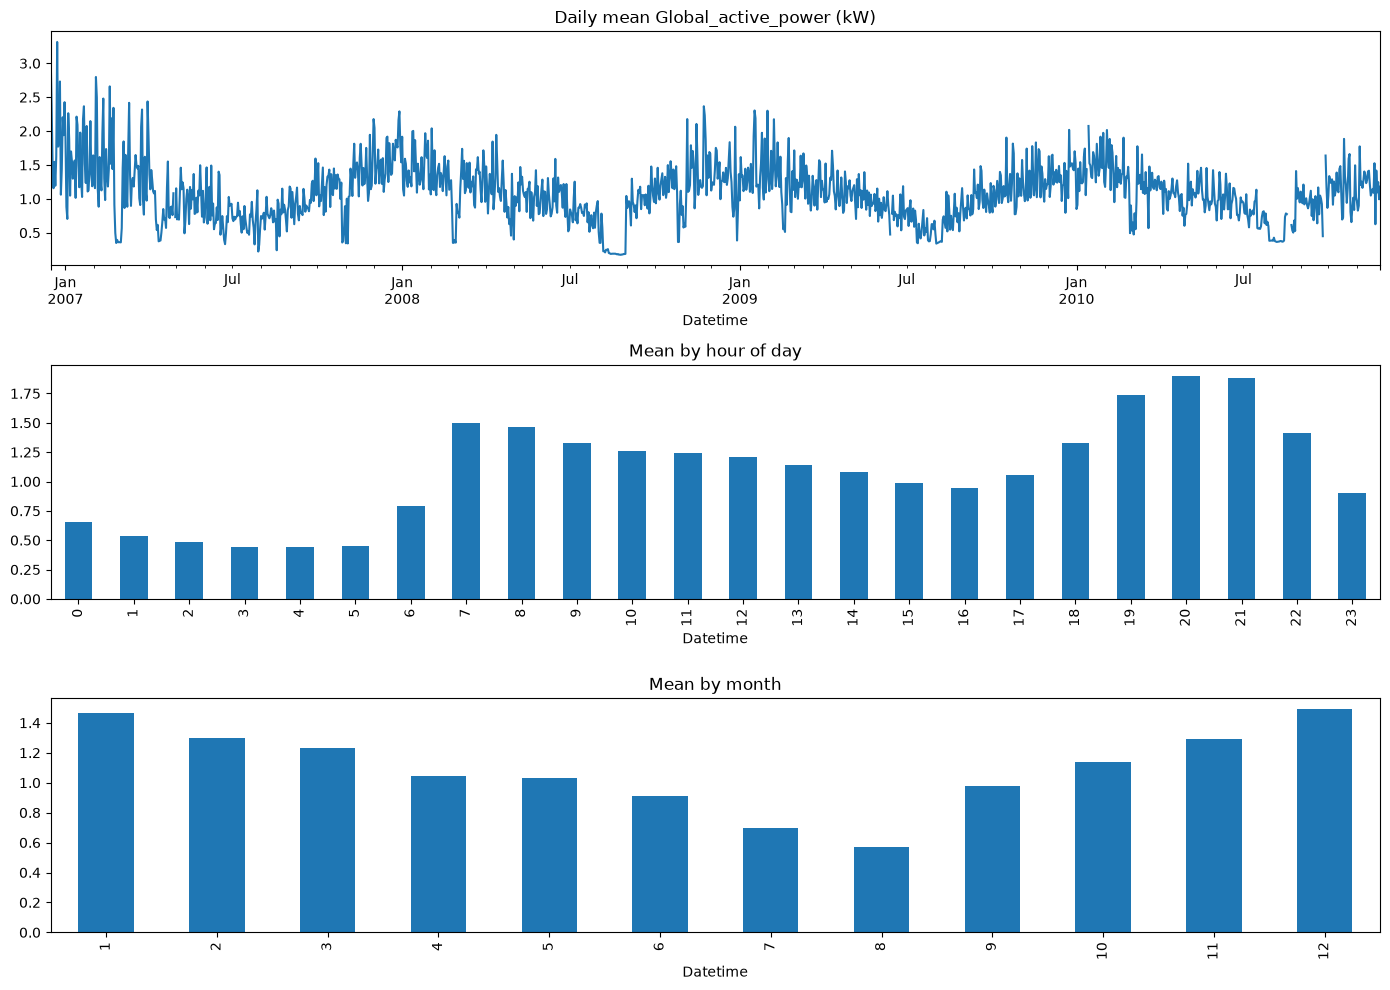

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10))
df['Global_active_power'].resample('D').mean().plot(ax=axes[0], title='Daily mean Global_active_power (kW)')
df['Global_active_power'].groupby(df.index.hour).mean().plot(ax=axes[1], kind='bar', title='Mean by hour of day')
df['Global_active_power'].groupby(df.index.month).mean().plot(ax=axes[2], kind='bar', title='Mean by month')
plt.tight_layout()
plt.show()

## Problem definition and data audit

| | |
|---|---|
| **Source** | UCI Individual Household Electric Power Consumption (#235), CC BY 4.0 |
| **Target** | `Global_active_power` (GAP), kW: the whole-house real power draw |
| **Native frequency** | 1 minute |
| **Resampling rule** | Hourly mean (an hour needs at least 30 recorded minutes, otherwise it counts as missing) |
| **Lookback / horizon** | 168 h (one week) in, next 24 h out |
| **Inputs** | Past 168 h of all 7 measured columns (lagged only) plus hour-of-day and day-of-week sin/cos |

**Operational meaning:** at hour *t* we forecast the household's load profile for the next day, using only data observed before *t*. That is the setting for day-ahead load planning and demand response.

In [10]:
TARGET = 'Global_active_power'
LOOKBACK, HORIZON = 168, 24
DAY, WEEK = 24, 168  # seasonal periods in hours

audit = pd.Series({
    'Target': f'{TARGET} (kW)',
    'Coverage': f'{df.index.min()} -> {df.index.max()}',
    'Rows (1 min)': len(df),
    'Duplicate timestamps': df.index.duplicated().sum(),
    'Missing rows': f'{row_missing.sum()} ({row_missing.mean():.2%})',
    'Missing gaps': len(gaps),
    'Longest gap': f"{gaps['minutes'].max() / 60 / 24:.1f} days",
    'Lookback / horizon': f'{LOOKBACK} h / {HORIZON} h',
}, name='Value')
audit.to_frame()

,Value
Target,Global_active_power (kW)
Coverage,2006-12-16 17:24:00 -> 2010-11-26 21:02:00
Rows (1 min),2075259
Duplicate timestamps,0
Missing rows,25979 (1.25%)
Missing gaps,71
Longest gap,5.0 days
Lookback / horizon,168 h / 24 h


## Resampling and imputation
* **Resample:** hourly mean. Hours with fewer than 30 recorded minutes are set to missing.
* **Short gaps (≤ 3 h):** forward fill, which carries the last observed hour forward.
* **Long gaps (up to about 5 days):** the value from the same hour one week earlier. Any remainder is forward-filled.

Every fill is **causal**: a missing hour is filled only from earlier hours. Interpolation would use the next observed hour, which could be a target hour of the same window. Nothing here is fitted to data either, so imputation cannot leak test statistics into training. The `imputed` mask is kept so we can report how much of each split is filled in.

In [11]:
counts = df[TARGET].resample('h').count()
hourly_raw = df.resample('h').mean()
hourly_raw.loc[counts < 30] = np.nan
imputed = hourly_raw[TARGET].isna()

# Length of each run of missing hours
run_id = (imputed != imputed.shift()).cumsum()
run_len = imputed.groupby(run_id).transform('size')
short_gap = imputed & (run_len <= 3)

hourly = hourly_raw.copy()
hourly.loc[short_gap] = hourly_raw.ffill().loc[short_gap]
for _ in range(2):  # a second pass covers gaps whose previous week was also missing
    hourly = hourly.fillna(hourly.shift(WEEK))
hourly = hourly.ffill().dropna()  # only leading hours with no history can remain; drop them
imputed = imputed.loc[hourly.index]

assert not hourly.isna().any().any()
print(f'Hourly rows: {len(hourly)} | imputed hours: {imputed.sum()} ({imputed.mean():.2%}), '
      f'of which short gaps: {short_gap.sum()}')

Hourly rows: 34589 | imputed hours: 432 (1.25%), of which short gaps: 7


## Why GAP is the target, and why the other measurements must be lagged
The charts below use the hourly data **before imputation**, so filled-in values can't create artificial correlation.

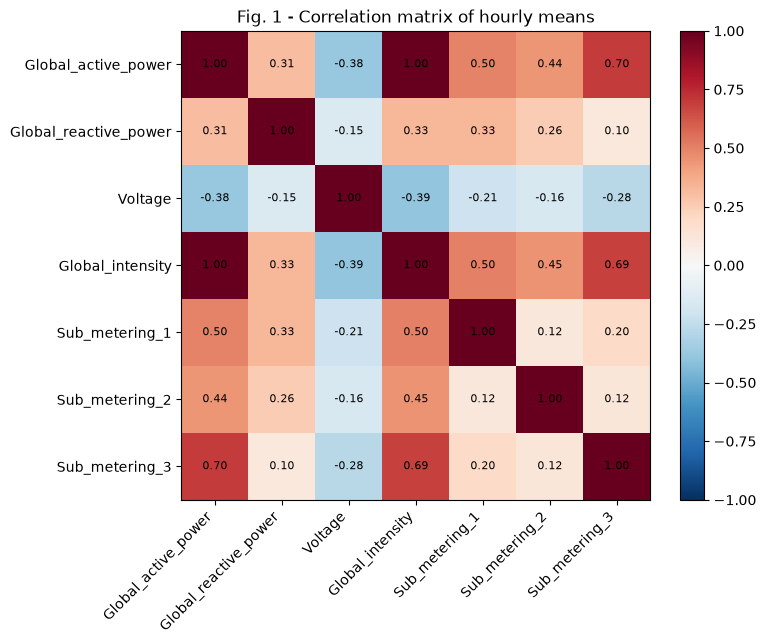

In [12]:
corr = hourly_raw.corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im, ax=ax)
ax.set_title('Fig. 1 - Correlation matrix of hourly means')
plt.tight_layout()
plt.show()

Sub-meters cover on average 38% of GAP


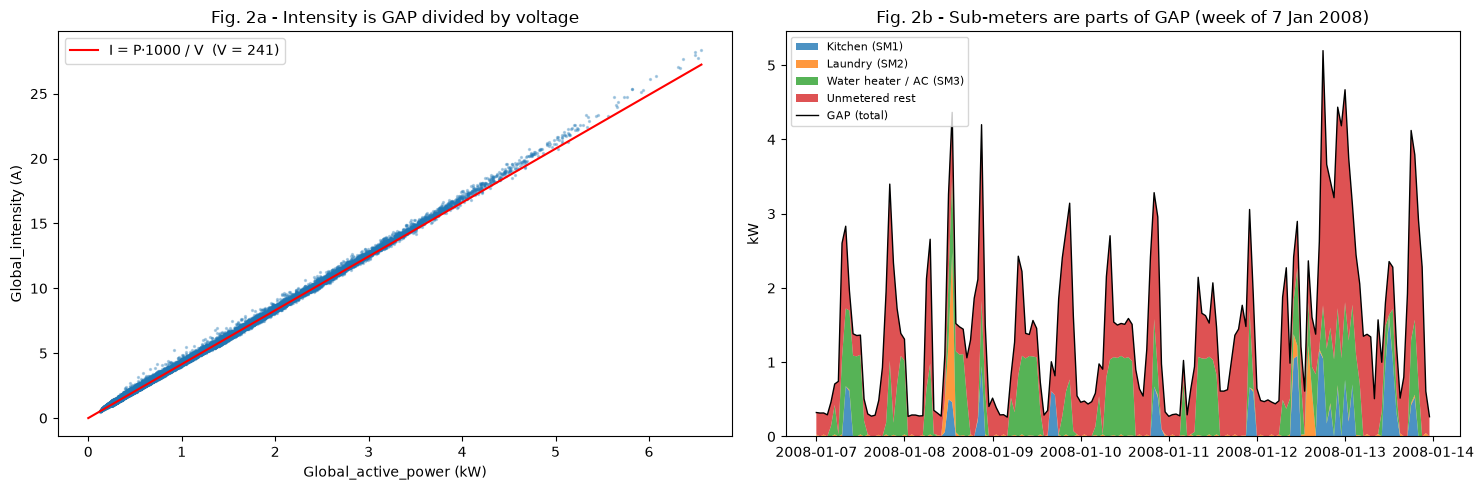

In [13]:
h = hourly_raw.dropna()
sub_cols = ['Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']

def sub_kw(frame):
    return frame[sub_cols] * 60 / 1000  # sub-meters are Wh per minute -> kW

print(f'Sub-meters cover on average {(sub_kw(h).sum(axis=1) / h[TARGET]).mean():.0%} of GAP')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

v = h['Voltage'].mean()
axes[0].scatter(h[TARGET], h['Global_intensity'], s=2, alpha=0.3)
x = np.linspace(0, h[TARGET].max(), 100)
axes[0].plot(x, x * 1000 / v, 'r', label=f'I = P·1000 / V  (V = {v:.0f})')
axes[0].set(xlabel='Global_active_power (kW)', ylabel='Global_intensity (A)',
            title='Fig. 2a - Intensity is GAP divided by voltage')
axes[0].legend()

week = hourly_raw.loc['2008-01-07':'2008-01-13']
parts = sub_kw(week)
parts.columns = ['Kitchen (SM1)', 'Laundry (SM2)', 'Water heater / AC (SM3)']
parts['Unmetered rest'] = week[TARGET] - parts.sum(axis=1)
axes[1].stackplot(parts.index, parts.T, labels=parts.columns, alpha=0.8)
axes[1].plot(week.index, week[TARGET], 'k', lw=1, label='GAP (total)')
axes[1].set(ylabel='kW', title='Fig. 2b - Sub-meters are parts of GAP (week of 7 Jan 2008)')
axes[1].legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

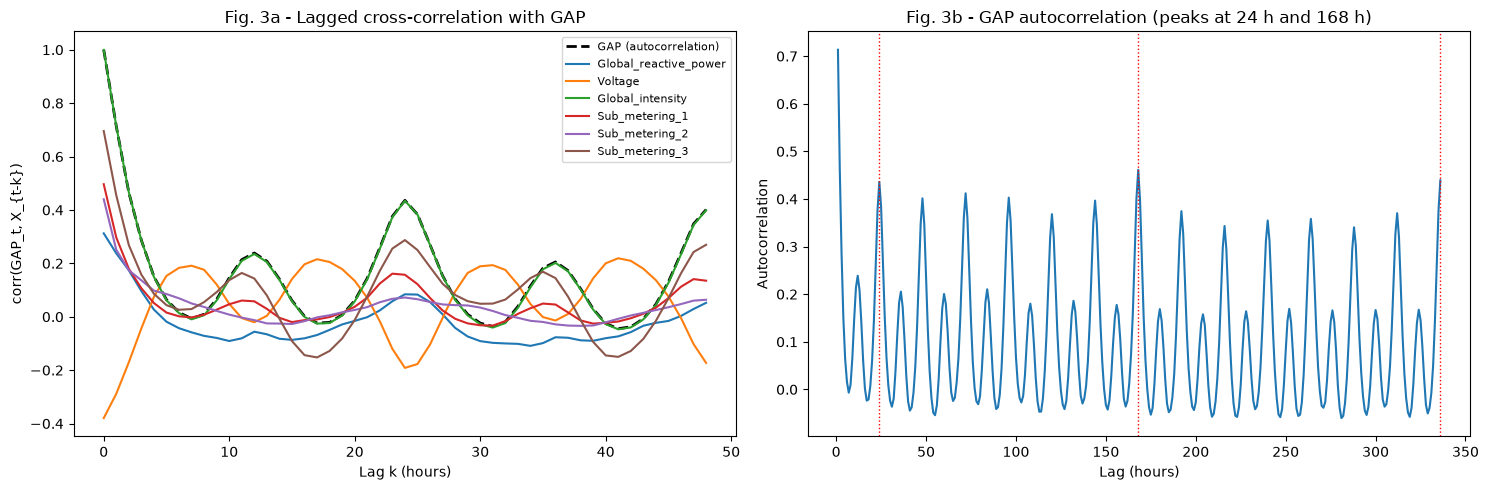

,lag 0 h,lag 1 h,lag 24 h,lag 48 h
Global_active_power,1.00,0.71,0.44,0.40
Global_reactive_power,0.31,0.24,0.08,0.05
Voltage,-0.38,-0.29,-0.19,-0.17
Global_intensity,1.00,0.71,0.43,0.40
Sub_metering_1,0.50,0.30,0.16,0.14
Sub_metering_2,0.44,0.25,0.07,0.06
Sub_metering_3,0.70,0.45,0.29,0.27


In [14]:
lags = range(49)
xcorr = pd.DataFrame({col: [hourly_raw[TARGET].corr(hourly_raw[col].shift(k)) for k in lags]
                      for col in hourly_raw.columns}, index=lags)
acf_lags = range(1, 2 * WEEK + 1)
acf = pd.Series([hourly_raw[TARGET].autocorr(k) for k in acf_lags], index=acf_lags)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for col in xcorr.columns:
    style = dict(color='k', ls='--', lw=2) if col == TARGET else {}
    label = 'GAP (autocorrelation)' if col == TARGET else col
    axes[0].plot(xcorr.index, xcorr[col], label=label, **style)
axes[0].set(xlabel='Lag k (hours)', ylabel='corr(GAP_t, X_{t-k})',
            title='Fig. 3a - Lagged cross-correlation with GAP')
axes[0].legend(fontsize=8)

axes[1].plot(acf.index, acf)
for k in (DAY, WEEK, 2 * WEEK):
    axes[1].axvline(k, color='r', ls=':', lw=1)
axes[1].set(xlabel='Lag (hours)', ylabel='Autocorrelation',
            title='Fig. 3b - GAP autocorrelation (peaks at 24 h and 168 h)')

plt.tight_layout()
plt.show()

xcorr.loc[[0, 1, 24, 48]].T.round(2).rename(columns=lambda k: f'lag {k} h')

**Why GAP is the target**
* GAP is the total real power the household draws, which is what the meter bills. That makes forecasting it directly useful.
* `Global_intensity` is the same quantity in amps (Fig. 1 r ≈ 1.00, Fig. 2a: it lies on I = P·1000/V). Forecasting it would be the same task in different units.
* The sub-meters only cover some circuits (Fig. 2b). A large "unmetered" share remains, so none of them describes the whole house.
* `Voltage` mostly reflects the grid, and `Global_reactive_power` isn't billed. Neither describes household consumption.

**Why the other measurements are lagged inputs only**
* At lag 0, `Global_intensity` is almost perfectly correlated with GAP (Fig. 3a). Feeding the same-hour value into the model would leak the answer: the "forecast" would just be a unit conversion. We wouldn't have that value at forecast time anyway.
* Once lagged (k ≥ 1), every feature's correlation falls to roughly GAP's own autocorrelation level or below. They add context (for example, which appliances were recently on) without revealing the target. This is the spec §3 rule: contemporaneous measurements may only be used as lagged inputs.
* The autocorrelation peaks at 24 h and 168 h (Fig. 3b) show daily and weekly cycles. That justifies a one-week lookback.

## Chronological split (60 / 20 / 20) and windows
* The split is by time, never shuffled globally. The scaler is **fit on training rows only**.
* Each window holds 168 hours of inputs (`t-168 … t-1`) and the 24 target hours `t … t+23`.
* For validation and test windows, the lookback may reach back into the previous split. That is past data, so it's allowed, but **targets always stay inside their own split**.

In [15]:
features = hourly.copy()
features['hour_sin'] = np.sin(2 * np.pi * features.index.hour / 24)
features['hour_cos'] = np.cos(2 * np.pi * features.index.hour / 24)
features['dow_sin'] = np.sin(2 * np.pi * features.index.dayofweek / 7)
features['dow_cos'] = np.cos(2 * np.pi * features.index.dayofweek / 7)
FEATURES = list(features.columns)
TARGET_IDX = FEATURES.index(TARGET)

n = len(features)
train_end, val_end = int(n * 0.6), int(n * 0.8)
splits = {'train': (0, train_end), 'val': (train_end, val_end), 'test': (val_end, n)}

pd.DataFrame([{'split': s, 'start': features.index[a], 'end': features.index[b - 1], 'hours': b - a,
               'imputed %': round(imputed.iloc[a:b].mean() * 100, 2)}
              for s, (a, b) in splits.items()]).set_index('split')

,start,end,hours,imputed %
split,,,,
train,2006-12-16 17:00:00,2009-04-29 09:00:00,20753,0.33
val,2009-04-29 10:00:00,2010-02-11 15:00:00,6918,1.76
test,2010-02-11 16:00:00,2010-11-26 21:00:00,6918,3.50


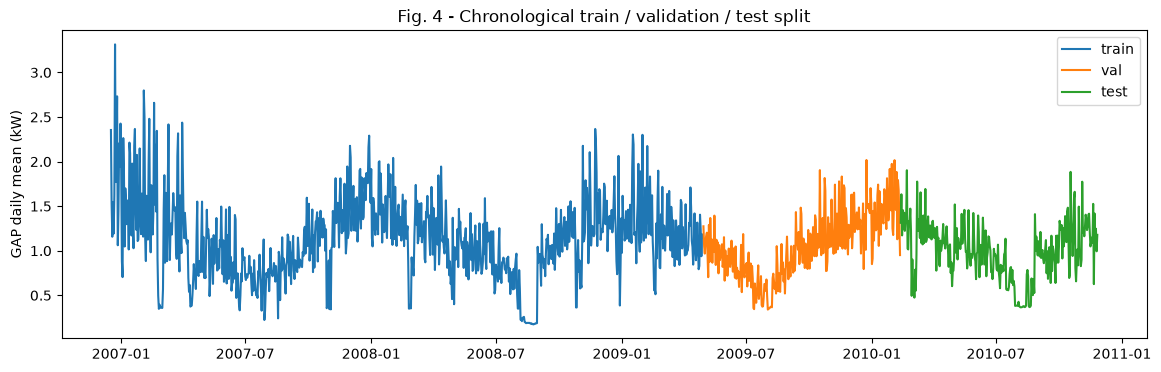

In [16]:
fig, ax = plt.subplots(figsize=(14, 4))
daily = features[TARGET].resample('D').mean()
for s, (a, b) in splits.items():
    part = daily.loc[features.index[a]:features.index[b - 1]]
    ax.plot(part.index, part, label=s)
ax.set(ylabel='GAP daily mean (kW)', title='Fig. 4 - Chronological train / validation / test split')
ax.legend()
plt.show()

In [17]:
from sklearn.preprocessing import StandardScaler

x_scaler = StandardScaler().fit(features.iloc[:train_end])  # train rows only
X_all = x_scaler.transform(features).astype(np.float32)

def to_kw(y):
    """Undo the target scaling so all metrics are in kW."""
    return y * x_scaler.scale_[TARGET_IDX] + x_scaler.mean_[TARGET_IDX]

def make_windows(start, end):
    """Windows whose 24-h target lies in rows [start, end); the lookback may come from earlier rows."""
    t = np.arange(max(start, LOOKBACK), end - HORIZON + 1)
    X = np.stack([X_all[i - LOOKBACK:i] for i in t])
    y = np.stack([X_all[i:i + HORIZON, TARGET_IDX] for i in t])
    return X, y, t

data = {s: make_windows(a, b) for s, (a, b) in splits.items()}
Y_kw = {s: to_kw(y) for s, (_, y, _) in data.items()}

for s, (X, y, t) in data.items():
    print(f'{s:5s}  X {X.shape}  y {y.shape}  targets {features.index[t[0]]} -> {features.index[t[-1] + HORIZON - 1]}')
X_train, y_train, t_train = data['train']
X_val, y_val, t_val = data['val']
assert X_train.shape[1:] == (LOOKBACK, len(FEATURES)) and y_train.shape[1] == HORIZON
assert t_train[-1] + HORIZON <= train_end and t_val[-1] + HORIZON <= val_end  # no target crosses a split

train  X (20562, 168, 11)  y (20562, 24)  targets 2006-12-23 17:00:00 -> 2009-04-29 09:00:00
val    X (6895, 168, 11)  y (6895, 24)  targets 2009-04-29 10:00:00 -> 2010-02-11 15:00:00
test   X (6895, 168, 11)  y (6895, 24)  targets 2010-02-11 16:00:00 -> 2010-11-26 21:00:00


## Baselines (non-neural)
All models make the same 24-hour forecast from the same windows and are scored in kW with MAE and RMSE.
* **Persistence:** repeat the last observed hour.
* **Seasonal naive (day):** the last 24 hours repeat.
* **Seasonal naive (week):** the same 24 hours one week earlier repeat.
* **Ridge regression** on the flattened 168 × 11 window. Alpha is chosen on validation.

Until the final comparison, only validation scores are shown. The test set stays untouched.

In [18]:
import time
from sklearn.linear_model import Ridge

def evaluate(y_true, y_pred):
    err = y_pred - y_true
    return {'MAE': np.abs(err).mean(), 'RMSE': np.sqrt((err ** 2).mean())}

def flat(X):
    return X.reshape(len(X), -1)

# Every model is registered once: a predictor (scaled windows -> scaled 24-h forecasts) plus its cost info
predictors, info, preds = {}, {}, {}

def register(name, predict_fn, params=0, secs=0.0, seed='-'):
    predictors[name] = predict_fn
    for split in data:  # drop forecasts cached from an earlier model with this name
        preds.pop((name, split), None)
    info[name] = {'params': params, 'train time (s)': secs, 'seed': seed}

def prediction(name, split):
    """kW forecasts of one model on one split, computed once and cached."""
    if (name, split) not in preds:
        preds[name, split] = to_kw(predictors[name](data[split][0]))
    return preds[name, split]

def score(split):
    return pd.DataFrame({name: evaluate(Y_kw[split], prediction(name, split))
                         for name in predictors}).T.add_prefix(f'{split} ')

def table(*splits):
    return pd.concat([score(s) for s in splits], axis=1).join(pd.DataFrame(info).T)

def seasonal_naive(period):
    """Forecast each hour with the value `period` hours earlier (taken from the lookback window)."""
    assert HORIZON <= period <= LOOKBACK
    return lambda X: X[:, LOOKBACK - period:LOOKBACK - period + HORIZON, TARGET_IDX]

register('Persistence', lambda X: np.repeat(X[:, -1:, TARGET_IDX], HORIZON, axis=1))
register('Seasonal naive (day)', seasonal_naive(DAY))
register('Seasonal naive (week)', seasonal_naive(WEEK))

Xf_train, Xf_val = flat(X_train), flat(X_val)
ridge_mae, ridge_fits = {}, {}
for alpha in [1, 10, 100, 1000, 10000]:
    start = time.perf_counter()
    model = Ridge(alpha=alpha).fit(Xf_train, y_train)
    ridge_fits[alpha] = (model, time.perf_counter() - start)
    ridge_mae[alpha] = evaluate(Y_kw['val'], to_kw(model.predict(Xf_val)))['MAE']
best_alpha = min(ridge_mae, key=ridge_mae.get)
print('Ridge validation MAE by alpha:', {a: round(m, 4) for a, m in ridge_mae.items()}, '-> alpha =', best_alpha)

ridge, ridge_secs = ridge_fits[best_alpha]
register('Ridge', lambda X: ridge.predict(flat(X)), ridge.coef_.size + ridge.intercept_.size, ridge_secs)

table('val')

c:\Users\jonat\.conda\envs\DeepLearning\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.8954192881892595e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


Ridge validation MAE by alpha: {1: np.float64(0.4538), 10: np.float64(0.452), 100: np.float64(0.4507), 1000: np.float64(0.4471), 10000: np.float64(0.4427)} -> alpha = 10000


,val MAE,val RMSE,params,train time (s),seed
Persistence,0.797540,1.089732,0,0.0,-
Seasonal naive (day),0.584761,0.866910,0,0.0,-
Seasonal naive (week),0.521579,0.790607,0,0.0,-
Ridge,0.442686,0.610559,44376,0.240496,-


## MLP and CNN (PyTorch)
Both use the same windows, horizon, loss (MSE on scaled GAP), optimizer (Adam), batch size and early-stopping rule (at most 100 epochs, stopping after 30 epochs without validation improvement, then restore the best weights). They are scored with the same metrics as the baselines.
* **MLP:** flattens the 168 × 11 window, then fully connected layers.
* **CNN:** two Conv1d + max-pool blocks slide over time. The result is flattened rather than globally averaged, so the model keeps track of *when* in the week a pattern happened.

In [19]:
import copy
from functools import partial
from torch import nn

BATCH = 64
MAX_EPOCHS, PATIENCE = 100, 30

class MLP(nn.Module):
    def __init__(self, hidden=256, layers=2, dropout=0.2):
        super().__init__()
        dims = [LOOKBACK * len(FEATURES)] + [hidden] * layers
        blocks = [nn.Flatten()]
        for d_in, d_out in zip(dims, dims[1:]):
            blocks += [nn.Linear(d_in, d_out), nn.ReLU(), nn.Dropout(dropout)]
        self.net = nn.Sequential(*blocks, nn.Linear(dims[-1], HORIZON))

    def forward(self, x):
        return self.net(x)

class CNN(nn.Module):
    def __init__(self, filters=64, kernel=5, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(len(FEATURES), filters, kernel, padding='same'), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(filters, filters, kernel, padding='same'), nn.ReLU(), nn.MaxPool1d(2),
            nn.Flatten(), nn.Dropout(dropout),
            nn.Linear(filters * (LOOKBACK // 4), HORIZON))

    def forward(self, x):
        return self.net(x.transpose(1, 2))  # (batch, time, features) -> (batch, channels, time)

# Grid-search spaces per model family (used in the grid search section)
MODEL_SPECS = {
    'MLP': (MLP, {'hidden': [128, 256, 512], 'layers': [1, 2], 'dropout': [0.0, 0.2],
                  'lr': [1e-3, 3e-4], 'batch_size': [32, 64, 128]}),
    'CNN': (CNN, {'filters': [32, 64, 128], 'kernel': [3, 5], 'dropout': [0.0, 0.2],
                  'lr': [1e-3, 3e-4], 'batch_size': [32, 64, 128]}),
}

def count_params(model):
    return sum(p.numel() for p in model.parameters())

def predict(model, X):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(xb.to(device)).cpu() for xb in torch.from_numpy(X).split(1024)]).numpy()

def register_model(name, model, secs):
    register(name, partial(predict, model), count_params(model), secs, SEED)

def fit(build, train, val, lr=1e-3, batch_size=BATCH, max_epochs=MAX_EPOCHS, patience=PATIENCE):
    """Train with early stopping on validation MSE; returns the best model, loss history and train time."""
    set_seed()
    model = build().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    # Copy the data to the device once, instead of once per batch
    X_tr, y_tr = (torch.from_numpy(a).to(device) for a in train)
    X_va, y_va = (torch.from_numpy(a).to(device) for a in val)
    history = {'train': [], 'val': []}
    best_loss, best_state, wait = float('inf'), copy.deepcopy(model.state_dict()), 0
    start = time.perf_counter()
    for _ in range(max_epochs):
        model.train()
        total = 0.0
        for idx in torch.randperm(len(X_tr), device=device).split(batch_size):
            opt.zero_grad()
            loss = loss_fn(model(X_tr[idx]), y_tr[idx])
            loss.backward()
            opt.step()
            total += loss.detach() * len(idx)
        model.eval()
        with torch.no_grad():
            val_loss = sum(loss_fn(model(xb), yb).item() * len(xb)
                           for xb, yb in zip(X_va.split(1024), y_va.split(1024))) / len(X_va)
        history['train'].append(total.item() / len(X_tr))
        history['val'].append(val_loss)
        if val_loss < best_loss:
            best_loss, wait = val_loss, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return model, history, time.perf_counter() - start

MLP: 31 epochs, 11.3 s
CNN: 31 epochs, 14.4 s


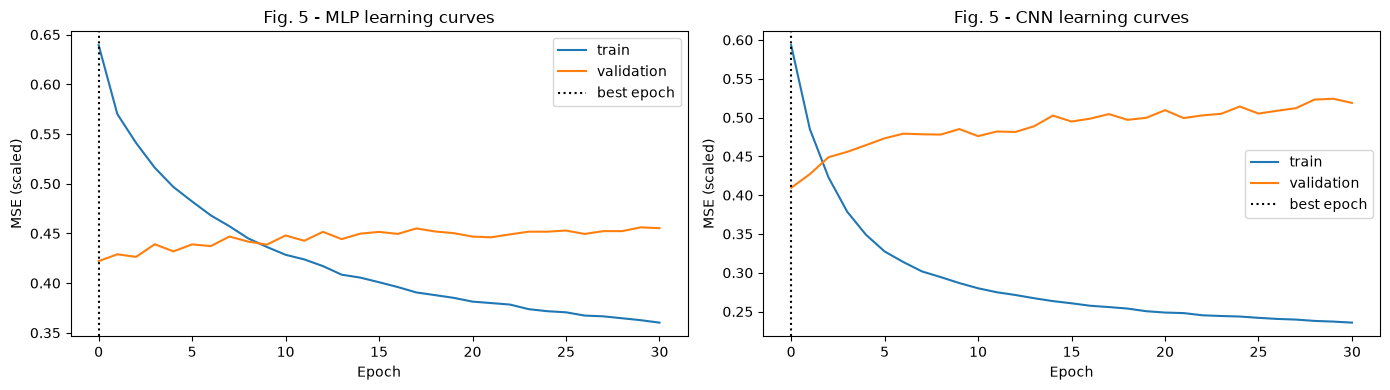

,val MAE,val RMSE,params,train time (s),seed
Persistence,0.797540,1.089732,0,0.0,-
Seasonal naive (day),0.584761,0.866910,0,0.0,-
Seasonal naive (week),0.521579,0.790607,0,0.0,-
Ridge,0.442686,0.610559,44376,0.240496,-
MLP,0.467375,0.623942,545304.0,11.297408,42.0
CNN,0.455504,0.614547,88664.0,14.44614,42.0


In [20]:
histories = {}
for name, (cls, _) in MODEL_SPECS.items():
    model, histories[name], secs = fit(cls, (X_train, y_train), (X_val, y_val))
    register_model(name, model, secs)
    print(f'{name}: {len(histories[name]["val"])} epochs, {secs:.1f} s')

fig, axes = plt.subplots(1, len(histories), figsize=(7 * len(histories), 4), squeeze=False)
for ax, (name, hist) in zip(axes[0], histories.items()):
    ax.plot(hist['train'], label='train')
    ax.plot(hist['val'], label='validation')
    ax.axvline(int(np.argmin(hist['val'])), color='k', ls=':', label='best epoch')
    ax.set(xlabel='Epoch', ylabel='MSE (scaled)', title=f'Fig. 5 - {name} learning curves')
    ax.legend()
plt.tight_layout()
plt.show()

val_scores = table('val')
val_scores

**Reading the learning curves:** if the validation loss bottoms out early while the training loss keeps falling, the model is overfitting. Early stopping keeps the weights from the best validation epoch (the dotted line).

## Grid search (validation only)
The model family (MLP or CNN) with the lower validation MAE above is tuned. The setup is fixed before any results are seen:
* **Objective:** validation MAE (kW).
* **Search space** (both families share lr and batch size):
  * MLP: hidden {128, 256, 512} × layers {1, 2} × dropout {0, 0.2}
  * CNN: filters {32, 64, 128} × kernel {3, 5} × dropout {0, 0.2}
  * Training: lr {1e-3, 3e-4} × batch size {32, 64, 128}
* **Budget:** 72 trials, at most 100 epochs each, early stopping with patience 30, seed 42.

The test set isn't used here.

In [21]:
import itertools
import os

family = val_scores.loc[list(MODEL_SPECS), 'val MAE'].idxmin()
cls, grid = MODEL_SPECS[family]
print('Tuning', family)

trials, best = [], {'val MAE': float('inf')}
for values in itertools.product(*grid.values()):
    cfg = dict(zip(grid, values))
    train_cfg = {k: cfg.pop(k) for k in ('lr', 'batch_size')}  # passed to fit(), not to the model
    model, hist, secs = fit(lambda: cls(**cfg), (X_train, y_train), (X_val, y_val), **train_cfg)
    mae = evaluate(Y_kw['val'], to_kw(predict(model, X_val)))['MAE']
    trials.append({**cfg, **train_cfg, 'val MAE': mae, 'epochs': len(hist['val']), 'train time (s)': secs})
    if mae < best['val MAE']:
        best = {'val MAE': mae, 'model': model, 'cfg': cfg, 'train_cfg': train_cfg, 'secs': secs}

trials = pd.DataFrame(trials)
trials.sort_values('val MAE').reset_index(drop=True)

Tuning CNN


,filters,kernel,dropout,lr,batch_size,val MAE,epochs,train time (s)
0,128,3,0.0,0.0003,64,0.438066,31,15.129629
1,64,3,0.0,0.0003,64,0.438466,32,13.813764
2,128,5,0.0,0.0003,128,0.438849,32,14.590872
3,128,5,0.0,0.0003,64,0.439526,31,17.428017
4,64,3,0.2,0.0010,64,0.439684,31,15.211334
...,...,...,...,...,...,...,...,...
67,128,3,0.0,0.0010,64,0.464586,31,15.198256
68,128,3,0.2,0.0010,64,0.464807,31,15.537864
69,64,5,0.0,0.0010,32,0.465508,31,27.733023
70,128,5,0.2,0.0010,32,0.466946,31,28.421281


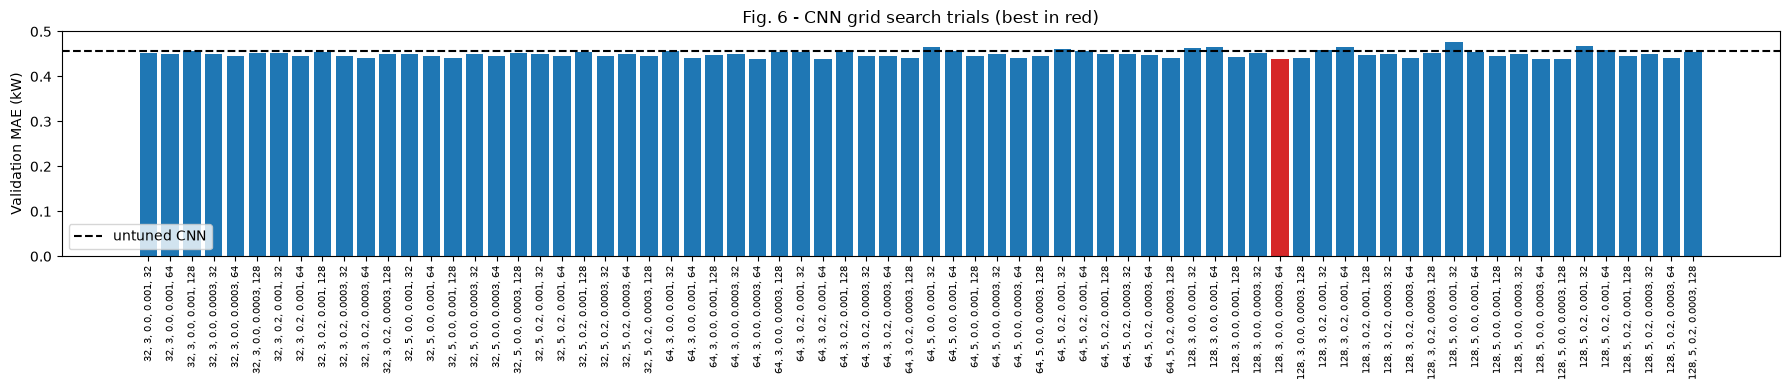

Best config: {'filters': 128, 'kernel': 3, 'dropout': 0.0} | {'lr': 0.0003, 'batch_size': 64} | val MAE 0.4381 kW -> saved to models/stage1_best.pt


In [22]:
fig, ax = plt.subplots(figsize=(max(12, 0.25 * len(trials)), 4))
labels = trials.drop(columns=['val MAE', 'epochs', 'train time (s)']).astype(str).agg(', '.join, axis=1)
ax.bar(range(len(trials)), trials['val MAE'], color=['C3' if m == best['val MAE'] else 'C0' for m in trials['val MAE']])
ax.axhline(val_scores.loc[family, 'val MAE'], color='k', ls='--', label=f'untuned {family}')
ax.set_xticks(range(len(trials)), labels, rotation=90, fontsize=7)
ax.set(ylabel='Validation MAE (kW)', title=f'Fig. 6 - {family} grid search trials (best in red)')
ax.legend()
plt.tight_layout()
plt.show()

tuned = f'{family} (tuned)'
register_model(tuned, best['model'], best['secs'])

os.makedirs('models', exist_ok=True)
torch.save({'family': family, 'config': best['cfg'], 'train_config': best['train_cfg'], 'state_dict': best['model'].state_dict(),
            'lookback': LOOKBACK, 'horizon': HORIZON, 'target': TARGET, 'features': FEATURES,
            'x_mean': x_scaler.mean_.tolist(), 'x_scale': x_scaler.scale_.tolist()},
           'models/stage1_best.pt')
print('Best config:', best['cfg'], '|', best['train_cfg'], f"| val MAE {best['val MAE']:.4f} kW -> saved to models/stage1_best.pt")

## Final comparison on the test set
All models are now locked, so the test set is evaluated **once**. "Improvement" is the test-MAE reduction relative to the better seasonal-naive baseline, where "better" was chosen on validation.

In [23]:
results = table('val', 'test')
reference = results.loc[['Seasonal naive (day)', 'Seasonal naive (week)'], 'val MAE'].idxmin()
results['improvement vs baseline (%)'] = 100 * (1 - results['test MAE'] / results.loc[reference, 'test MAE'])
print('Table 1 - Model comparison (kW). Reference baseline:', reference)
results.round(4)

Table 1 - Model comparison (kW). Reference baseline: Seasonal naive (week)


,val MAE,val RMSE,test MAE,test RMSE,params,train time (s),seed,improvement vs baseline (%)
Persistence,0.7975,1.0897,0.7103,0.9678,0,0.0,-,-30.4384
Seasonal naive (day),0.5848,0.8669,0.5266,0.7820,0,0.0,-,3.3059
Seasonal naive (week),0.5216,0.7906,0.5446,0.8017,0,0.0,-,0.0000
Ridge,0.4427,0.6106,0.4415,0.5941,44376,0.240496,-,18.9335
MLP,0.4674,0.6239,0.4639,0.6052,545304.0,11.297408,42.0,14.8087
CNN,0.4555,0.6145,0.4543,0.5934,88664.0,14.44614,42.0,16.5692
CNN (tuned),0.4381,0.6118,0.4364,0.5952,182680.0,15.129629,42.0,19.8618


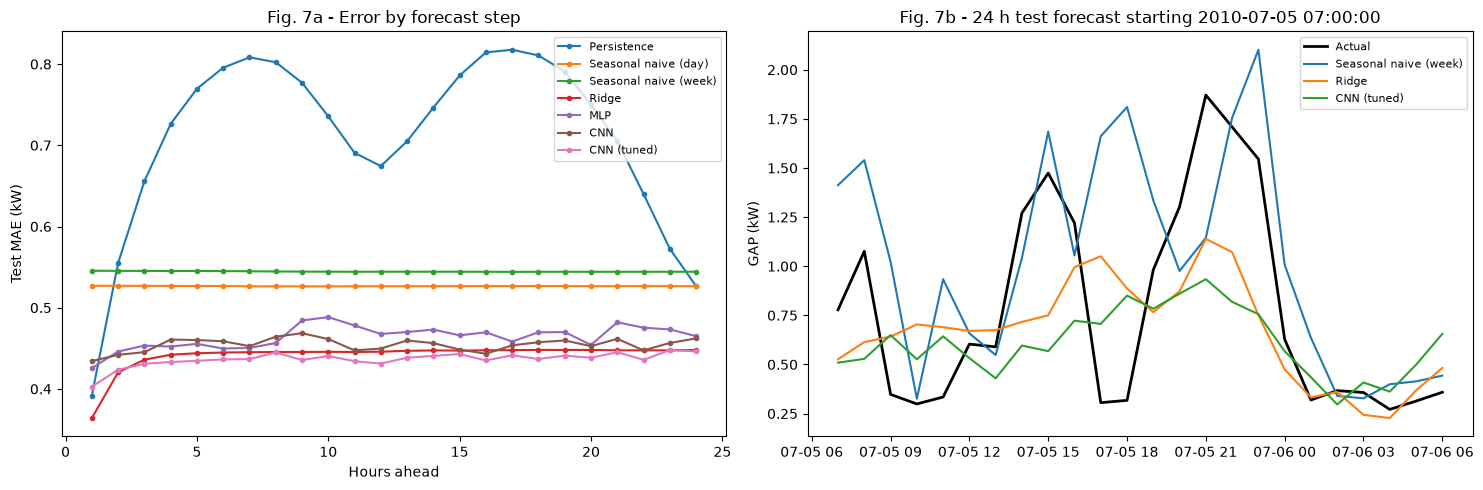

In [24]:
X_test, _, t_test = data['test']

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name in predictors:
    step_mae = np.abs(prediction(name, 'test') - Y_kw['test']).mean(axis=0)
    axes[0].plot(range(1, HORIZON + 1), step_mae, marker='.', label=name)
axes[0].set(xlabel='Hours ahead', ylabel='Test MAE (kW)', title='Fig. 7a - Error by forecast step')
axes[0].legend(fontsize=8)

i = len(X_test) // 2  # fixed rule (middle of the test set), chosen before looking at forecasts
hours = features.index[t_test[i]:t_test[i] + HORIZON]
axes[1].plot(hours, Y_kw['test'][i], 'k', lw=2, label='Actual')
for name in [reference, 'Ridge', tuned]:
    axes[1].plot(hours, prediction(name, 'test')[i], label=name)
axes[1].set(ylabel='GAP (kW)', title=f'Fig. 7b - 24 h test forecast starting {hours[0]}')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Conclusion and next risk
**Conclusion:** The tuned CNN reaches a test MAE of 0.436 kW, 19.9% better than the seasonal-naive (week) reference. But Ridge gets 0.442 kW with a quarter of the parameters and 1/50 of the training time, and has a slightly lower RMSE. So most of the gain over the naive baselines comes from a *linear* weighting of the past week, and the CNN adds only about 0.005 kW. On test, seasonal naive (day) turns out to be the stronger naive baseline (0.527), and the tuned CNN still beats it by 17.1%.

**Unresolved risk to investigate next:**The test split is the most heavily imputed part of the data (3.50% of hours, vs 0.33% in training). It includes the two longest gaps (Aug and Sep 2010, about 5 days each), which were filled with the previous week's values, so part of the test score measures how well the model reproduces our own imputation rather than real consumption. Next we will report test metrics with imputed hours excluded. We also plan an ablation that removes features which may add little once lagged (voltage, reactive power and the sub-meters, whose lagged correlation with GAP is at or below GAP's own autocorrelation), to check whether they help beyond past GAP. The series has strong daily and weekly cycles and a yearly trend, so we will test whether making it stationary helps, either by having the model predict the change from the same hour last week or by using a seasonal decomposition. The decomposition must be computed causally from the lookback window only, because a full-series STL would leak future values. Finally, early stopping consistently selected weights from the first few epochs, which suggests the models overfit almost immediately. Recurrent and attention-based models (LSTM/GRU, Transformer) may use the 168-hour sequence better than the flattened MLP or fixed-window CNN.

## Smoke test
A quick end-to-end check for the TA, which takes seconds and doesn't need the grid search to be re-run:
1. Reload the saved checkpoint and predict with it.
2. Train the same architecture for one epoch on 2,000 windows.

In [25]:
ckpt = torch.load('models/stage1_best.pt', map_location=device)
smoke_cls = MODEL_SPECS[ckpt['family']][0]

reloaded = smoke_cls(**ckpt['config']).to(device)
reloaded.load_state_dict(ckpt['state_dict'])

X_s, y_s = X_train[:2000], y_train[:2000]
smoke_model, _, _ = fit(lambda: smoke_cls(**ckpt['config']), (X_s, y_s), (X_s[:200], y_s[:200]),
                        max_epochs=1, **ckpt['train_config'])

for out in (predict(reloaded, X_val[:200]), predict(smoke_model, X_val[:200])):
    assert out.shape == (200, HORIZON) and np.isfinite(out).all()
print('Smoke test passed on', device, '| output shape', out.shape)

Smoke test passed on cuda | output shape (200, 24)
